# CQF Exam 2 — Monte Carlo option pricing

**Module 3, Summer 2026**  
**Name:** Lingxiao Li  
**Date:** 19 September 2026

This notebook prices European call and put options by Monte Carlo simulation. It compares Euler–Maruyama, Milstein and exact geometric Brownian motion (GBM), then studies sampling error, time-discretisation error, antithetic variates and the option Greeks. The report is organised directly around the assessment marking scheme: Introduction, Results, Discussion, Conclusion and References.


## Original question

> **Assignment for Module 3 — Summer 2026**
>
> **Instructions:** This is a mini project on the use of the Monte Carlo scheme to price various call options, to be completed using Python. No other language is allowed. As this is the half way point of the CQF, this assessment is designed for delegates to show independence and maturity in interpretation of a slightly open ended problem. It will test:
>
> - finding and understanding the relevant lectures, Python labs and tutorials in Module 3, as well as the Python primer;
> - ability to experiment and demonstrate initiative in mathematical and numerical methods;
> - willingness to work outside narrow instructions that are typical of maths-based tests/exams.
>
> **Task**
>
> Use the expected value of the discounted payoff under the risk-neutral density $Q$,
>
> $$V(S,t)=e^{-r(T-t)}\mathbb{E}^{Q}[\text{Payoff}],$$
>
> for the appropriate form of payoff, to consider the pricing of plain vanilla call and put options.
>
> Use the Euler–Maruyama scheme, Milstein scheme and closed-form solution for simulating the underlying stock price. As an initial example you may use the following sample data:
>
> - Today's stock price $S_0=100$
> - Strike $E=100$
> - Time to expiry $(T-t)=1$ year
> - Volatility $\sigma=20\%$
> - Constant risk-free interest rate $r=5\%$
>
> A good idea would be to seed the random numbers.
>
> Repeat the above with the antithetic variates variance-reduction technique.
>
> Then vary the data to see the effect on the option price. This entails a study of the Greeks.
>
> The completed assignment should centre on a report containing:
>
> - Introduction — outline of the finance problem and numerical procedure used. **[20%]**
> - Results — appropriate tables, error analysis, graphs and comparisons. **[35%]**
> - Interesting observations, problems encountered and discussion of results. **[20%]**
> - Detailed conclusion. **[20%]**
> - References. **[5%]**
>
> For a Python Jupyter Notebook, a detailed notebook will become the complete report (write-up, code and results). No other format of Python will be accepted.
>
> **Score key:** 60–65 Pass; 66–70 Good; 71–79 Very Good; 80–89 Excellent; 90–95 Outstanding; 96+ Exceptional.
>
> **Note:** An assessment of this form differs from mathematical exercises that can attract full marks. The key above is provided for this reason.

*The wording above is transcribed from the supplied exam sheet. I use $K$ for the strike below rather than $E$.*

## 1. Introduction — finance problem and numerical procedure [20%]

### 1.1 Problem and objective

A European option pays a function of the stock price at a fixed expiry date. The pricing problem is to determine the value of that future payoff today. Under the Black–Scholes assumptions, this can be written as the discounted risk-neutral expectation

$$
V_0=e^{-rT}\mathbb{E}^{Q}[g(S_T)].
$$

The practical procedure is therefore to simulate many possible terminal stock prices under the risk-neutral measure, apply the payoff to every simulated value, average the payoffs and discount the result. The strike belongs to the option payoff and does not affect the simulated dynamics of the stock.

The aim of this project is to compare Euler–Maruyama, Milstein and exact GBM simulation for European calls and puts. Black–Scholes prices are used as analytical benchmarks. The study then separates Monte Carlo sampling error from time-discretisation error, measures the benefit of antithetic variates, and varies the inputs to examine the Greeks.


### 1.2 Literature review

Black and Scholes [1] and Merton [2] developed the continuous-time no-arbitrage framework that leads to analytical prices for European options. Under the model assumptions, the stock is lognormally distributed and the option value can be expressed either through the Black–Scholes formula or as a discounted expectation under the risk-neutral measure.

The CQF stochastic-differential-equation notes [3] introduce GBM, its exact exponential solution and the Euler construction. The Module 3 numerical-methods notes [4] show that GBM is a special case for which the transition distribution is known exactly. With constant $r$ and $\sigma$, the SDE can therefore be simulated using an exact exponential time step rather than a numerical approximation. These sources motivate the comparison between numerical time stepping and exact simulation in this project.

Monte Carlo pricing and antithetic sampling are developed in the CQF tutorial and Python material [5, 8]. Glasserman [6] gives a broader treatment of Monte Carlo pricing, variance reduction, discretisation and sensitivity estimation. A basic Monte Carlo estimator converges at the statistical rate $N^{-1/2}$, so improving accuracy only by increasing the number of paths is relatively expensive.

Strong convergence was not a major emphasis of the supplied lecture material, but it provides a useful additional way to compare Euler and Milstein. Higham [7] shows that Euler has strong order $1/2$, while Milstein has strong order 1 under the usual conditions. This is a pathwise statement and is not the same as convergence of an expected option payoff. The CQF Black–Scholes lab [9] and the `quantmod` documentation [10] are used as implementation checks rather than as substitutes for the theoretical sources.


### 1.3 Model, payoffs and assumptions

In the real-world GBM model [3],

$$
dS_t=\mu S_t\,dt+\sigma S_t\,dW_t.
$$

For derivative pricing, the real-world drift $\mu$ is replaced by the risk-free rate $r$. Under the risk-neutral measure $Q$,

$$
dS_t=rS_t\,dt+\sigma S_t\,dW_t^Q.
$$

This distribution is used for pricing and is not a forecast of the stock's actual return. The European call and put payoffs are

$$
C_T=\max(S_T-K,0),
\qquad
P_T=\max(K-S_T,0),
$$

giving

$$
C_0=e^{-rT}\mathbb{E}^Q[C_T],
\qquad
P_0=e^{-rT}\mathbb{E}^Q[P_T].
$$

The model assumes constant $r$ and $\sigma$ within each valuation, no dividends, European exercise and GBM stock dynamics. The inputs are varied between valuations later in the notebook, but they remain constant through time inside each individual simulation.


### 1.4 Simulation schemes

Let $\Delta t=T/M$ and $\Delta W_n=\sqrt{\Delta t}Z_n$, where $Z_n\sim N(0,1)$.

**Euler–Maruyama** [3, 7]

$$
S_{n+1}
=
S_n+rS_n\Delta t+\sigma S_n\Delta W_n.
$$

Euler–Maruyama uses the drift and Brownian increment directly over each small interval.

**Milstein** [7]

$$
S_{n+1}
=
S_n+rS_n\Delta t+\sigma S_n\Delta W_n
+\frac12\sigma^2S_n\left[(\Delta W_n)^2-\Delta t\right].
$$

Milstein includes an additional stochastic correction. For GBM, it follows from the diffusion coefficient $b(S)=\sigma S$ and derivative $b'(S)=\sigma$.

**Exact GBM** [3, 4]

$$
S_{n+1}
=
S_n\exp\left[
\left(r-\frac12\sigma^2\right)\Delta t
+\sigma\Delta W_n
\right].
$$

Since a European option only depends on the terminal value, the whole period can also be simulated directly:

$$
S_T
=
S_0\exp\left[
\left(r-\frac12\sigma^2\right)T
+\sigma\sqrt{T}Z
\right],
\qquad Z\sim N(0,1).
$$

Euler and Milstein are numerical approximations to the same GBM SDE, not different stock-price models. The exact exponential solution is available because the coefficients are constant and the SDE has the GBM form. Exact simulation still has Monte Carlo sampling error, but it has no time-discretisation error.


### 1.5 Monte Carlo estimator and uncertainty

Let the discounted payoff from simulation $i$ be

$$
X_i=e^{-rT}g(S_T^{(i)}).
$$

The Monte Carlo estimator is

$$
\widehat V=\frac{1}{N}\sum_{i=1}^{N}X_i.
$$

If the independent discounted payoffs have variance $\sigma_X^2$, then

$$
\operatorname{Var}(\widehat V)=\frac{\sigma_X^2}{N}.
$$

Since $\sigma_X$ is unknown, it is replaced by the sample standard deviation $s_X$. The reported standard error and approximate 95% confidence interval are therefore

$$
\widehat{SE}(\widehat V)=\frac{s_X}{\sqrt{N}},
\qquad
\widehat V\pm1.96\,\widehat{SE}(\widehat V).
$$

The central limit theorem motivates this large-sample interval [5, 6]. It measures Monte Carlo sampling uncertainty only; it does not include the time-discretisation bias of Euler or Milstein.


#### Antithetic sampling and common random numbers

For antithetic sampling, each normal draw $Z$ is paired with $-Z$. If $X(Z)$ is one discounted payoff, the independent observation used by the estimator is the pair average

$$
Y=\frac{X(Z)+X(-Z)}{2}.
$$

If the two payoffs have variance $\sigma_X^2$ and within-pair correlation $\rho$, then

$$
\operatorname{Var}(Y)=\frac{\sigma_X^2}{2}(1+\rho).
$$

In this notebook `n_paths` is the total simulation budget. Plain Monte Carlo therefore averages $N$ individual payoffs, whereas the antithetic estimator averages $N/2$ independent pair averages. For the same total number of simulated paths,

$$
\operatorname{Var}(\widehat V_{\mathrm{plain}})=\frac{\sigma_X^2}{N},
\qquad
\operatorname{Var}(\widehat V_{\mathrm{AV}})=\frac{\sigma_X^2(1+\rho)}{N}.
$$

Antithetic sampling helps when the paired payoffs are negatively correlated [6, 8]. Where two methods or two bumped inputs are compared, the same underlying normal draws are also reused. These common random numbers reduce irrelevant noise in the difference between the two calculations.


### 1.6 Implementation and experimental design

The baseline experiment is summarised below.

| Item | Baseline choice |
|---|---:|
| Spot price $S_0$ | 100 |
| Strike $K$ | 100 |
| Time to expiry $T$ | 1 year |
| Volatility $\sigma$ | 20% |
| Risk-free rate $r$ | 5% |
| Monte Carlo paths $N$ | 50,000 |
| Time steps $M$ | 64 |
| Options | European call and put |
| Simulation schemes | Euler, Milstein and exact GBM |
| Analytical benchmark | Black–Scholes |
| Variance reduction | Antithetic variates |

Fixed seeds are used so that the displayed outputs and the numerical values quoted in the report are reproducible. The draws within each experiment are still different pseudorandom observations. Two functions are used: `simulate_terminal` generates $S_T$, while `mc_price` applies the payoff, discounts it and calculates the standard error and confidence interval.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

plt.style.use('seaborn-v0_8-whitegrid')
pd.options.display.float_format = '{:,.6f}'.format

In [2]:
S0 = 100.0
K = 100.0
T = 1.0
r = 0.05
sigma = 0.20

n_paths = 50_000
n_steps = 64
seed = 2026

print('dt =', T/n_steps)
print('paths =', n_paths)

dt = 0.015625
paths = 50000


In [3]:
def simulate_terminal(S0, T, r, sigma, Z, method):
    n_steps = Z.shape[1]
    dt = T/n_steps
    # Z has one row per path and one column per time step
    dW = np.sqrt(dt)*Z

    # For exact GBM, summing dW gives the total Brownian increment W_T
    if method == 'exact':
        return S0*np.exp((r-0.5*sigma**2)*T + sigma*dW.sum(axis=1))

    if method not in ['euler', 'milstein']:
        raise ValueError("method must be 'euler', 'milstein' or 'exact'")

    S = np.full(Z.shape[0], S0, dtype=float)
    for j in range(n_steps):
        if method == 'euler':
            S = S + r*S*dt + sigma*S*dW[:, j]
        else:
            S = (S + r*S*dt + sigma*S*dW[:, j]
                 + 0.5*sigma**2*S*(dW[:, j]**2-dt))
    return S


def mc_price(S0, K, T, r, sigma, method='exact', option='call',
             n_paths=50_000, n_steps=64, antithetic=False, seed=2026):
    rng = np.random.default_rng(seed)
    # For antithetic sampling, half as many Z draws are needed because
    # each draw generates the pair Z and -Z
    n = n_paths//2 if antithetic else n_paths
    Z = rng.standard_normal((n, n_steps))

    ST = simulate_terminal(S0, T, r, sigma, Z, method)
    if option == 'call':
        payoff = np.maximum(ST-K, 0)
    elif option == 'put':
        payoff = np.maximum(K-ST, 0)
    else:
        raise ValueError("option must be 'call' or 'put'")

    if antithetic:
        ST_a = simulate_terminal(S0, T, r, sigma, -Z, method)
        if option == 'call':
            payoff_a = np.maximum(ST_a-K, 0)
        else:
            payoff_a = np.maximum(K-ST_a, 0)
        payoff = 0.5*(payoff+payoff_a)

    discounted = np.exp(-r*T)*payoff
    price = discounted.mean()
    se = discounted.std(ddof=1)/np.sqrt(len(discounted))
    return price, se, price-1.96*se, price+1.96*se

## 2. Results — tables, error analysis, graphs and comparisons [35%]

### 2.1 Black–Scholes benchmark and no-arbitrage check

Under the same assumptions, the analytical call and put prices are [1, 2, 9]

$$
C_{BS}=S_0N(d_1)-Ke^{-rT}N(d_2),
\qquad
P_{BS}=Ke^{-rT}N(-d_2)-S_0N(-d_1),
$$

where

$$
d_1=\frac{\ln(S_0/K)+(r+\frac12\sigma^2)T}{\sigma\sqrt{T}},
\qquad
d_2=d_1-\sigma\sqrt{T}.
$$

Here, $N(x)$ is the standard normal cumulative distribution function, implemented as `norm.cdf`. These prices are exact benchmarks within the Black–Scholes model rather than another simulation method.


In [4]:
def black_scholes(S0, K, T, r, sigma, option='call'):
    d1 = (np.log(S0/K) + (r+0.5*sigma**2)*T) / (sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)

    if option == 'call':
        return S0*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)
    if option == 'put':
        return K*np.exp(-r*T)*norm.cdf(-d2) - S0*norm.cdf(-d1)
    raise ValueError("option must be 'call' or 'put'")


bs_call = black_scholes(S0, K, T, r, sigma, 'call')
bs_put = black_scholes(S0, K, T, r, sigma, 'put')

print(f'Black-Scholes call = {bs_call:.6f}')
print(f'Black-Scholes put  = {bs_put:.6f}')
print(f'Put-call parity error = {bs_call-bs_put-S0+K*np.exp(-r*T):.2e}')

Black-Scholes call = 10.450584
Black-Scholes put  = 5.573526
Put-call parity error = 0.00e+00


The analytical values are

$$
C_{BS}=10.450584,
\qquad
P_{BS}=5.573526.
$$

The zero numerical put–call parity error checks

$$
C_0-P_0=S_0-Ke^{-rT}.
$$

Rearranging gives $S_0+P_0-C_0=Ke^{-rT}$. The corresponding portfolio—long one stock and one put, and short one call—pays the certain amount $K$ at expiry. Put–call parity is therefore a useful no-arbitrage consistency check for the pricing functions.


### 2.2 Baseline Monte Carlo prices

Euler–Maruyama, Milstein and exact GBM are used to price the call and put, both with and without antithetic variates. For each calculation the table reports the estimated price, Monte Carlo standard error and approximate 95% confidence interval.

The signed and percentage errors are

$$
\text{signed error}=\widehat V_{\mathrm{MC}}-V_{\mathrm{BS}},
$$

$$
\text{relative error}=100\,
\frac{\widehat V_{\mathrm{MC}}-V_{\mathrm{BS}}}{V_{\mathrm{BS}}}.
$$

A positive signed error means the estimate is above Black–Scholes. `ci_contains_bs` is `True` when the analytical value lies inside the reported interval. This flag refers only to estimated sampling uncertainty and should not be interpreted as a test that discretisation bias is absent.


In [5]:
# Fixed seed keeps the reported table reproducible. The same seed is used
# for all methods so that their differences are less affected by random draws.
run_seed = 1631378084
print('Seed used:', run_seed)

rows = []

for antithetic in [False, True]:
    for method in ['euler', 'milstein', 'exact']:
        for option in ['call', 'put']:
            price, se, low, high = mc_price(
                S0, K, T, r, sigma, method, option,
                n_paths, n_steps, antithetic, run_seed
            )

            benchmark = bs_call if option == 'call' else bs_put
            error = price - benchmark

            rows.append([
                method, option, antithetic,
                price, se, low, high,
                error,
                100*error/benchmark,
                low <= benchmark <= high
            ])

baseline = pd.DataFrame(rows, columns=[
    'method', 'option', 'antithetic',
    'price', 'standard_error',
    'ci_low', 'ci_high',
    'signed_error',
    'relative_error_pct',
    'ci_contains_bs'
])

baseline

Seed used: 1631378084


,method,option,antithetic,price,standard_error,ci_low,ci_high,signed_error,relative_error_pct,ci_contains_bs
0,euler,call,False,10.495623,0.066028,10.366209,10.625037,0.045040,0.430977,True
1,euler,put,False,5.591316,0.038816,5.515237,5.667395,0.017790,0.319186,True
2,milstein,call,False,10.491406,0.066135,10.361781,10.621031,0.040823,0.390628,True
3,milstein,put,False,5.585911,0.038731,5.509999,5.661823,0.012385,0.222212,True
4,exact,call,False,10.498523,0.066191,10.368789,10.628256,0.047939,0.458723,True
5,exact,put,False,5.591055,0.038761,5.515084,5.667026,0.017529,0.314499,True
6,euler,call,True,10.430767,0.046289,10.340041,10.521492,-0.019817,-0.189626,True
7,euler,put,True,5.561082,0.029713,5.502845,5.619320,-0.012444,-0.223263,True
8,milstein,call,True,10.425494,0.046444,10.334464,10.516524,-0.025090,-0.240082,True
9,milstein,put,True,5.555687,0.029614,5.497644,5.613731,-0.017839,-0.320060,True


The next figure displays the same estimates. Each point is a Monte Carlo price, each vertical error bar is the approximate 95% confidence interval, and the dashed line is the corresponding Black–Scholes value. Labels containing `AV` use antithetic variates. Shorter error bars indicate lower sampling uncertainty.


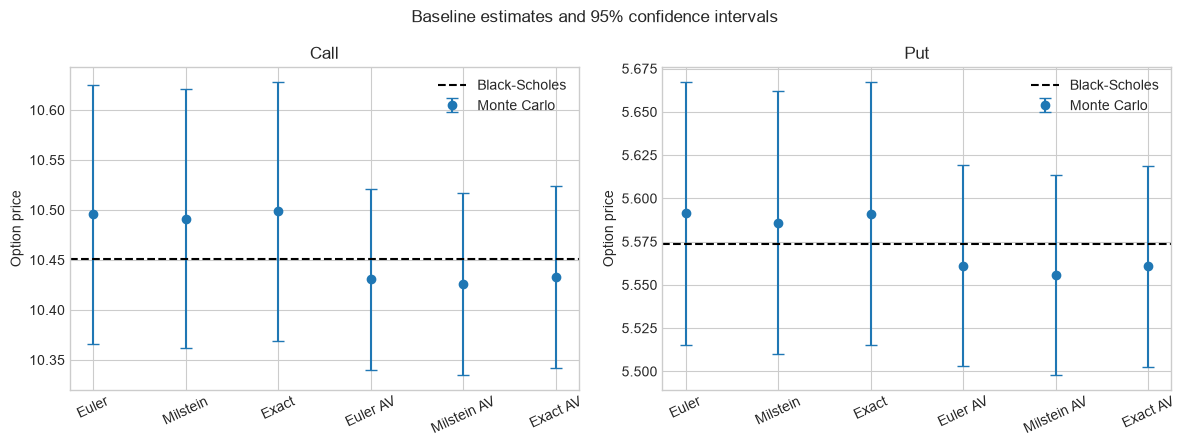

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, option, benchmark in zip(axes, ['call', 'put'], [bs_call, bs_put]):
    data = baseline[baseline['option']==option]
    labels = [m.title()+(' AV' if av else '')
              for m, av in zip(data['method'], data['antithetic'])]
    ax.errorbar(labels, data['price'], yerr=1.96*data['standard_error'],
                fmt='o', capsize=4, label='Monte Carlo')
    ax.axhline(benchmark, color='black', linestyle='--', label='Black-Scholes')
    ax.set_ylabel('Option price')
    ax.set_title(option.title())
    ax.tick_params(axis='x', rotation=25)
    ax.legend()

fig.suptitle('Baseline estimates and 95% confidence intervals')
plt.tight_layout()
plt.show()

#### Baseline findings

All twelve intervals contain the corresponding Black–Scholes value in this run, and the largest absolute value of the reported percentage error is below $0.5\%$. At $M=64$, differences between the three simulation schemes are small compared with ordinary Monte Carlo uncertainty. The antithetic estimates have visibly smaller standard errors and shorter intervals for both options.

Although exact GBM samples from the correct terminal distribution, its price remains a finite-sample Monte Carlo estimate and therefore does not exactly equal Black–Scholes. In this run, the plain and antithetic estimates lie on opposite sides of the analytical value. Their quality should be assessed through sampling variance and standard error over repeated runs, rather than by which estimate happens to be closest in one simulation.

### 2.3 Error analysis

Two numerical effects must be separated [4, 6, 7]. Sampling error arises because an expectation is estimated with finitely many paths and decreases approximately as $N^{-1/2}$. Euler and Milstein also have time-discretisation error because the continuous process is approximated with finite time steps. More paths do not remove a time-step bias, and more time steps do not remove ordinary sampling noise.

#### 2.3.1 Monte Carlo sampling convergence

Exact GBM is used here to remove time-discretisation error. For each path count $N$, the complete call valuation is repeated 50 times with different seeds. The repeated estimates provide the between-run standard deviation and RMSE relative to Black–Scholes, which can be compared with the average standard error reported inside the individual runs.


In [7]:
path_counts = [500, 1000, 2000, 5000, 10_000, 25_000, 50_000]
sampling_rows = []

# Fixed base seed makes the repeated experiment reproducible
sampling_seed = 396679771
print('Sampling experiment seed:', sampling_seed)

for N in path_counts:
    estimates = []
    reported_se = []
    for j in range(50):
        price, se, low, high = mc_price(
            S0, K, T, r, sigma, 'exact', 'call', N, 1, False, sampling_seed+j
        )
        estimates.append(price)
        reported_se.append(se)

    estimates = np.array(estimates)
    rmse = np.sqrt(np.mean((estimates-bs_call)**2))
    sampling_rows.append([N, estimates.mean(), estimates.std(ddof=1),
                          np.mean(reported_se), rmse])

sampling = pd.DataFrame(sampling_rows, columns=[
    'n_paths', 'mean_price', 'sd_between_runs', 'mean_reported_se', 'rmse'
])
sampling

Sampling experiment seed: 396679771


,n_paths,mean_price,sd_between_runs,mean_reported_se,rmse
0,500,10.414780,0.571072,0.657345,0.566465
1,1000,10.449388,0.373321,0.467175,0.369571
2,2000,10.462320,0.286823,0.329832,0.284183
3,5000,10.461017,0.200856,0.208406,0.199111
4,10000,10.483239,0.163462,0.147643,0.165081
5,25000,10.488320,0.099501,0.093395,0.105482
6,50000,10.470244,0.073187,0.065946,0.075072


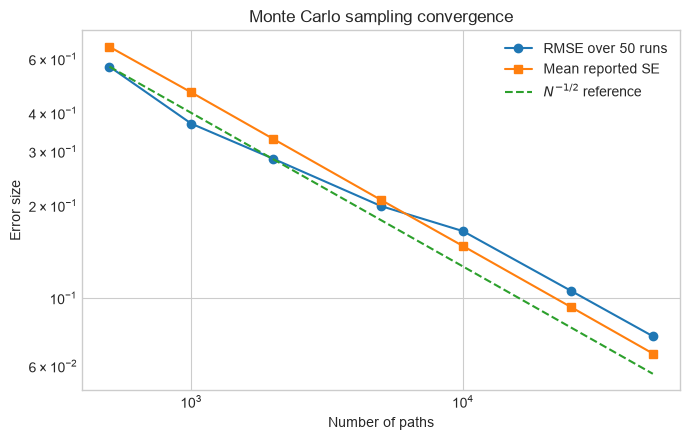

In [8]:
reference = sampling['rmse'].iloc[0]*np.sqrt(path_counts[0]/np.array(path_counts))

plt.figure(figsize=(7, 4.5))
plt.loglog(sampling['n_paths'], sampling['rmse'], 'o-', label='RMSE over 50 runs')
plt.loglog(sampling['n_paths'], sampling['mean_reported_se'], 's-', label='Mean reported SE')
plt.loglog(path_counts, reference, '--', label=r'$N^{-1/2}$ reference')
plt.xlabel('Number of paths')
plt.ylabel('Error size')
plt.title('Monte Carlo sampling convergence')
plt.legend()
plt.tight_layout()
plt.show()

The RMSE broadly follows the $N^{-1/2}$ reference. Increasing the number of paths from 500 to 50,000, a factor of 100, reduces the mean reported standard error from $0.657$ to $0.066$, close to the expected factor of ten. The empirical RMSE falls from $0.566$ to $0.075$. Its small fluctuations around the reference are reasonable because every plotted point is based on only 50 repeated valuations. The between-run standard deviation and the mean reported standard error are of similar size, supporting the use of $s_X/\sqrt{N}$ as the measure of sampling uncertainty.


#### 2.3.2 Time-step convergence of Euler and Milstein

The second experiment fixes the path count at $N=80{,}000$ and increases the number of time steps $M$, where

$$
\Delta t=\frac{T}{M}.
$$

At each value of $M$, Euler, Milstein and exact GBM use the same Brownian increments. The strong terminal error is estimated as

$$
\frac{1}{N}\sum_{i=1}^{N}
\left|S_{T,i}^{\mathrm{scheme}}-S_{T,i}^{\mathrm{exact}}\right|.
$$

“Strong” means that the approximate and exact terminal values are compared on the same Brownian path. The expected rates from the numerical-SDE literature are [7]

$$
\text{Euler error}\propto(\Delta t)^{1/2},
\qquad
\text{Milstein error}\propto\Delta t.
$$

The discounted call payoff is also compared path by path. For scheme $s$,

$$
D_i^s=e^{-rT}\left[
\max(S_{T,i}^s-K,0)-
\max(S_{T,i}^{\mathrm{exact}}-K,0)
\right].
$$

The mean of $D_i^s$ estimates the option-price difference and $s_D/\sqrt{N}$ is its paired standard error.


In [9]:
step_counts = [1, 2, 4, 8, 16, 32, 64, 128]
time_rows = []
n_error_paths = 80_000

# Fixed seed makes the time-step comparison reproducible
time_seed = 3637603363
print('Time-step experiment seed:', time_seed)

rng = np.random.default_rng(time_seed)

for M in step_counts:
    # Generate an (N, M) matrix of independent standard-normal shocks.
    Z = rng.standard_normal((n_error_paths, M))

    # Reuse this same Z matrix for exact GBM, Euler and Milstein
    # so that terminal values and payoffs can be compared path by path
    ST_exact = simulate_terminal(S0, T, r, sigma, Z, 'exact')
    ST_euler = simulate_terminal(S0, T, r, sigma, Z, 'euler')
    ST_milstein = simulate_terminal(S0, T, r, sigma, Z, 'milstein')

    strong_euler = np.mean(abs(ST_euler-ST_exact))
    strong_milstein = np.mean(abs(ST_milstein-ST_exact))

    exact_payoff = np.exp(-r*T)*np.maximum(ST_exact-K, 0)
    euler_difference = np.exp(-r*T)*np.maximum(ST_euler-K, 0) - exact_payoff
    milstein_difference = np.exp(-r*T)*np.maximum(ST_milstein-K, 0) - exact_payoff

    time_rows.append([
        M, T/M, strong_euler, strong_milstein,
        euler_difference.mean(),
        euler_difference.std(ddof=1)/np.sqrt(n_error_paths),
        milstein_difference.mean(),
        milstein_difference.std(ddof=1)/np.sqrt(n_error_paths)
    ])

time_error = pd.DataFrame(time_rows, columns=[
    'n_steps', 'dt', 'strong_euler', 'strong_milstein',
    'call_diff_euler', 'call_diff_euler_se',
    'call_diff_milstein', 'call_diff_milstein_se'
])

time_error

Time-step experiment seed: 3637603363


,n_steps,dt,strong_euler,strong_milstein,call_diff_euler,call_diff_euler_se,call_diff_milstein,call_diff_milstein_se
0,1,1.000000,2.057297,0.713390,-0.263106,0.009573,-0.401642,0.002750
1,2,0.500000,1.549813,0.387824,-0.096706,0.006321,-0.213647,0.001410
2,4,0.250000,1.127434,0.205898,-0.041925,0.004279,-0.110473,0.000719
3,8,0.125000,0.821856,0.106782,-0.021095,0.003055,-0.056132,0.000370
4,16,0.062500,0.585269,0.054282,-0.009948,0.002140,-0.028050,0.000186
5,32,0.031250,0.417575,0.027364,-0.004589,0.001521,-0.014130,0.000093
6,64,0.015625,0.296529,0.013875,-0.001162,0.001077,-0.007163,0.000047
7,128,0.007812,0.210755,0.006940,-0.001729,0.000765,-0.003587,0.000024


Estimated strong order: Euler 0.491, Milstein 0.986


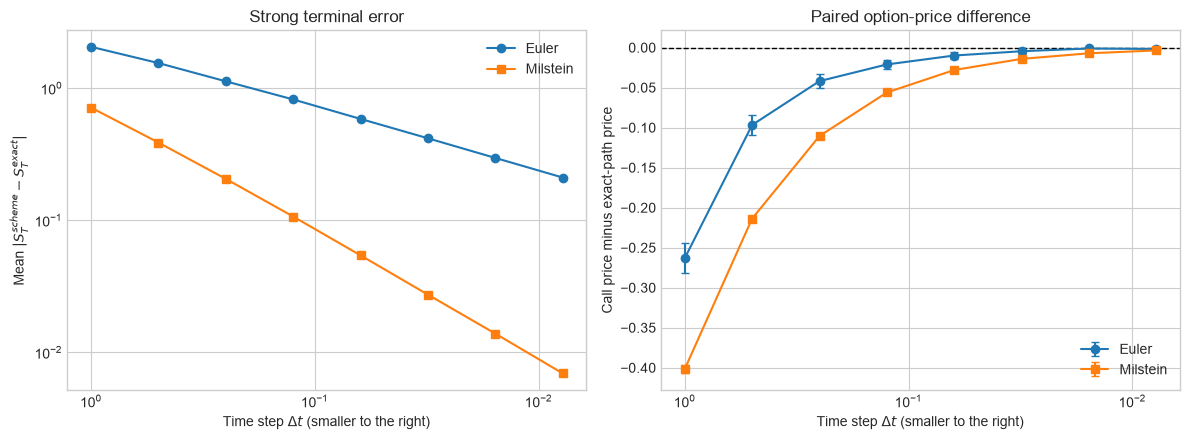

,n_steps,dt,strong_euler,strong_milstein,call_diff_euler,call_diff_milstein
Coarsest grid,1,1.000000,2.057297,0.713390,-0.263106,-0.401642
Finest grid,128,0.007812,0.210755,0.006940,-0.001729,-0.003587


In [10]:
fine = time_error.iloc[-5:]
euler_order = np.polyfit(np.log(fine['dt']), np.log(fine['strong_euler']), 1)[0]
milstein_order = np.polyfit(np.log(fine['dt']), np.log(fine['strong_milstein']), 1)[0]
print(f'Estimated strong order: Euler {euler_order:.3f}, Milstein {milstein_order:.3f}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].loglog(time_error['dt'], time_error['strong_euler'], 'o-', label='Euler')
axes[0].loglog(time_error['dt'], time_error['strong_milstein'], 's-', label='Milstein')
axes[0].invert_xaxis()
axes[0].set_xlabel(r'Time step $\Delta t$ (smaller to the right)')
axes[0].set_ylabel(r'Mean $|S_T^{scheme}-S_T^{exact}|$')
axes[0].set_title('Strong terminal error')
axes[0].legend()

axes[1].errorbar(time_error['dt'], time_error['call_diff_euler'],
                 yerr=1.96*time_error['call_diff_euler_se'],
                 fmt='o-', capsize=3, label='Euler')
axes[1].errorbar(time_error['dt'], time_error['call_diff_milstein'],
                 yerr=1.96*time_error['call_diff_milstein_se'],
                 fmt='s-', capsize=3, label='Milstein')
axes[1].axhline(0, color='black', linestyle='--', linewidth=1)
axes[1].set_xscale('log')
axes[1].invert_xaxis()
axes[1].set_xlabel(r'Time step $\Delta t$ (smaller to the right)')
axes[1].set_ylabel('Call price minus exact-path price')
axes[1].set_title('Paired option-price difference')
axes[1].legend()

plt.tight_layout()
plt.show()

# Values quoted in the discussion
selected_points = time_error.iloc[[0, -1]][[
    'n_steps', 'dt', 'strong_euler', 'strong_milstein',
    'call_diff_euler', 'call_diff_milstein'
]].copy()

selected_points.index = ['Coarsest grid', 'Finest grid']
display(selected_points)

The fitted strong orders are $0.491$ for Euler and $0.986$ for Milstein, close to the theoretical values $1/2$ and 1. At $\Delta t=1$, the mean terminal-price errors are $2.057$ and $0.713$. At $\Delta t=1/128$, they decrease to $0.211$ and $0.00694$, so Milstein is much more accurate path by path.

Both paired call-price differences also approach zero. On the one-step grid, Euler and Milstein are respectively $0.263$ and $0.402$ below the exact-path price. At 128 steps, these differences fall to $0.00173$ and $0.00359$. Milstein's smaller strong error therefore does not automatically make its option-price difference smaller on every grid.


### 2.4 Antithetic variance reduction

The benefit of antithetic sampling is measured from the estimator variance rather than from which price is closest to Black–Scholes in one run. Since estimator variance is the square of its standard error, the estimated variance-reduction factor is

$$
\text{VRF}=
\frac{\operatorname{Var}(\widehat V_{\mathrm{plain}})}
{\operatorname{Var}(\widehat V_{\mathrm{AV}})}
=
\left(\frac{SE_{\mathrm{plain}}}{SE_{\mathrm{AV}}}\right)^2.
$$

A factor greater than one indicates an improvement. Exact GBM gives the cleanest assessment because no time-discretisation error is present, although the table includes all three schemes.


In [11]:
# Separate the plain and antithetic results for every method and option
plain = (
    baseline[~baseline['antithetic']]
    .set_index(['method', 'option'])
)

anti = (
    baseline[baseline['antithetic']]
    .set_index(['method', 'option'])
)

# Compare their standard errors
av_table = pd.DataFrame({
    'plain_se': plain['standard_error'],
    'antithetic_se': anti['standard_error']
})

# Variance is proportional to the square of the standard error
av_table['variance_reduction_factor'] = (
    av_table['plain_se'] / av_table['antithetic_se']
)**2

av_table = av_table.reset_index()
av_table

,method,option,plain_se,antithetic_se,variance_reduction_factor
0,euler,call,0.066028,0.046289,2.034714
1,euler,put,0.038816,0.029713,1.706579
2,milstein,call,0.066135,0.046444,2.027723
3,milstein,put,0.038731,0.029614,1.710488
4,exact,call,0.066191,0.046490,2.027114
5,exact,put,0.038761,0.029634,1.710849


For exact GBM, the variance-reduction factor is approximately $2.03$ for the call and $1.71$ for the put. Equivalently, the standard error is reduced by about $30\%$ and $24\%$ at the same total path budget. The factors are almost unchanged across Euler, Milstein and exact GBM, indicating that the benefit comes from the sampling construction rather than the time-stepping scheme.

Using $\text{VRF}\approx1/(1+\rho)$, the exact-GBM factors correspond to within-pair payoff correlations of roughly $-0.51$ for the call and $-0.42$ for the put. Antithetic sampling is symmetric in $Z$, but the exponential GBM mapping is skewed and the call and put select different parts of the terminal distribution. Put–call parity constrains expected prices, not the variances of the separate estimators.


### 2.5 Parameter variation and Greeks

The inputs are varied one at a time while the others remain at their baseline values. Exact GBM with antithetic variates is used so that the plots mainly show financial sensitivity rather than time-step error. Changing $S_0$ shows delta and gamma, changing $\sigma$ shows vega, changing $r$ shows rho, and changing remaining maturity $T$ is related to theta.


In [12]:
base = {'S0': S0, 'K': K, 'T': T, 'r': r, 'sigma': sigma}
sweeps = {
    'S0': np.linspace(60, 140, 17),
    'sigma': np.linspace(0.05, 0.60, 17),
    'r': np.linspace(0.00, 0.10, 17),
    'T': np.linspace(0.10, 2.00, 17)
}

rows = []
# Vary one parameter at a time while holding the others at their
# baseline values. The same seed gives the valuations common random
# numbers, making the Monte Carlo sensitivity curves less noisy.
for parameter, values in sweeps.items():
    for value in values:
        p = base.copy()
        p[parameter] = float(value)
        for option in ['call', 'put']:
            mc = mc_price(p['S0'], p['K'], p['T'], p['r'], p['sigma'],
                          'exact', option, 30_000, 1, True, seed)[0]
            bs = black_scholes(p['S0'], p['K'], p['T'], p['r'], p['sigma'], option)
            rows.append([parameter, value, option, mc, bs])

sensitivity = pd.DataFrame(rows, columns=[
    'parameter', 'value', 'option', 'mc_price', 'bs_price'
])

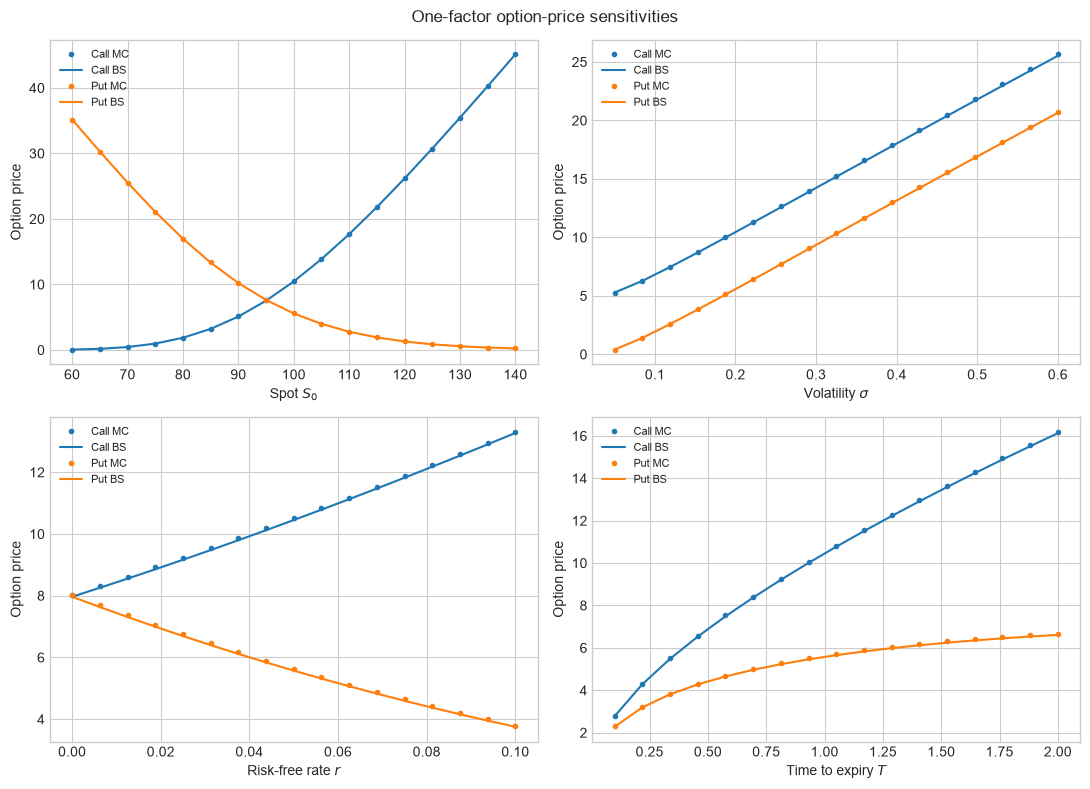

In [13]:
labels = {'S0': r'Spot $S_0$', 'sigma': r'Volatility $\sigma$',
          'r': r'Risk-free rate $r$', 'T': r'Time to expiry $T$'}
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

for ax, parameter in zip(axes.ravel(), sweeps):
    for option, colour in [('call', 'tab:blue'), ('put', 'tab:orange')]:
        data = sensitivity[(sensitivity['parameter']==parameter) &
                           (sensitivity['option']==option)]
        ax.plot(data['value'], data['mc_price'], 'o', ms=3, color=colour,
                label=option.title()+' MC')
        ax.plot(data['value'], data['bs_price'], '-', color=colour,
                label=option.title()+' BS')
    ax.set_xlabel(labels[parameter])
    ax.set_ylabel('Option price')
    ax.legend(fontsize=8)

fig.suptitle('One-factor option-price sensitivities')
plt.tight_layout()
plt.show()

#### Broad sensitivity patterns

The Monte Carlo points lie close to the Black–Scholes curves throughout the four sweeps.

**Delta $\Delta=\partial V/\partial S_0$ and gamma $\Gamma=\partial^2V/\partial S_0^2$:** As spot increases from $60$ to $140$, the call rises from almost zero to about $45$, while the put falls from about $35$ to almost zero. The call has positive delta and the put has negative delta. A deeply in-the-money call has delta approaching one, so its price curve becomes approximately parallel to $y=x$. Both curves are convex, giving positive gamma, with the strongest curvature near the strike.

**Vega $\nu=\partial V/\partial\sigma$:** Higher volatility raises both call and put prices because it broadens the terminal distribution while the option payoff is bounded below by zero. Put–call parity does not depend on volatility, so differentiating it with respect to $\sigma$ gives equal call and put vegas. The analytical call and put curves are therefore parallel.

**Rho $\rho=\partial V/\partial r$:** The call has positive rho and the put has negative rho. A higher interest rate reduces the present value of the strike, $Ke^{-rT}$, benefiting the call and reducing the put value. At $r=0$, call and put prices are equal here because $S_0=K$.

**Theta $\Theta=\partial V/\partial t$:** Both prices increase with remaining maturity $T$ over the plotted range. Conventional theta measures calendar time passing, so

$$
\Theta=\frac{\partial V}{\partial t}=-\frac{\partial V}{\partial T}.
$$

The sign of theta is therefore opposite to the slope in the maturity plot. At the baseline point both options lose value as expiry approaches.


#### Local numerical Greek estimates

The plots show broad trends. Local Greeks at the baseline point are also estimated with central finite differences. Each pair of bumped valuations uses the same random seed, exact GBM and antithetic sampling, so common random numbers reduce noise in the price difference. Vega and rho are reported for a one-percentage-point change, while theta is the approximate change over one calendar day. The analytical formulas follow the CQF Black–Scholes lab [9].


In [14]:
d1 = (np.log(S0/K) + (r+0.5*sigma**2)*T) / (sigma*np.sqrt(T))
d2 = d1 - sigma*np.sqrt(T)
gamma_bs = norm.pdf(d1)/(S0*sigma*np.sqrt(T))
vega_bs = S0*norm.pdf(d1)*np.sqrt(T)/100

analytic_greeks = pd.DataFrame({
    'call': [
        norm.cdf(d1),
        gamma_bs,
        vega_bs,
        (-S0*norm.pdf(d1)*sigma/(2*np.sqrt(T))
         - r*K*np.exp(-r*T)*norm.cdf(d2))/365,
        K*T*np.exp(-r*T)*norm.cdf(d2)/100
    ],
    'put': [
        norm.cdf(d1)-1,
        gamma_bs,
        vega_bs,
        (-S0*norm.pdf(d1)*sigma/(2*np.sqrt(T))
         + r*K*np.exp(-r*T)*norm.cdf(-d2))/365,
        -K*T*np.exp(-r*T)*norm.cdf(-d2)/100
    ]
}, index=['delta', 'gamma', 'vega per 1%', 'theta per day', 'rho per 1%']).T

In [15]:
hS = 0.5
h_sigma = 0.005
h_r = 0.0005
h_T = 1/365
greek_paths = 200_000
greek_rows = []

# Apply central finite-difference bumps around the baseline parameters.
# Reusing the same seed gives each up-and-down valuation the same
# normal draws, reducing noise in the estimated price difference.
for option in ['call', 'put']:
    value = mc_price(S0, K, T, r, sigma, 'exact', option,
                     greek_paths, 1, True, seed)[0]
    spot_up = mc_price(S0+hS, K, T, r, sigma, 'exact', option,
                       greek_paths, 1, True, seed)[0]
    spot_down = mc_price(S0-hS, K, T, r, sigma, 'exact', option,
                         greek_paths, 1, True, seed)[0]
    vol_up = mc_price(S0, K, T, r, sigma+h_sigma, 'exact', option,
                      greek_paths, 1, True, seed)[0]
    vol_down = mc_price(S0, K, T, r, sigma-h_sigma, 'exact', option,
                        greek_paths, 1, True, seed)[0]
    rate_up = mc_price(S0, K, T, r+h_r, sigma, 'exact', option,
                       greek_paths, 1, True, seed)[0]
    rate_down = mc_price(S0, K, T, r-h_r, sigma, 'exact', option,
                         greek_paths, 1, True, seed)[0]
    maturity_up = mc_price(S0, K, T+h_T, r, sigma, 'exact', option,
                           greek_paths, 1, True, seed)[0]
    maturity_down = mc_price(S0, K, T-h_T, r, sigma, 'exact', option,
                             greek_paths, 1, True, seed)[0]
    
    # Negative derivative with respect to remaining maturity, reported per day
    theta_per_day = -(maturity_up-maturity_down)/(2*h_T)/365

    greek_rows.append([
        option,
        (spot_up-spot_down)/(2*hS),
        (spot_up-2*value+spot_down)/hS**2,
        (vol_up-vol_down)/(2*h_sigma)*0.01,
        theta_per_day,
        (rate_up-rate_down)/(2*h_r)*0.01
    ])

mc_greeks = pd.DataFrame(greek_rows, columns=[
    'option', 'delta', 'gamma', 'vega per 1%', 'theta per day', 'rho per 1%'
]).set_index('option')

# Combine the Monte Carlo and analytical results into one table
greek_comparison = pd.concat([
    mc_greeks.stack().rename('Monte Carlo'),
    analytic_greeks.stack().rename('Black-Scholes')
], axis=1)

greek_comparison.index.names = ['option', 'greek']
greek_comparison

Monte Carlo  Black-Scholes
option greek                                    
call   delta             0.636477       0.636831
       gamma             0.018991       0.018762
       vega per 1%       0.373837       0.375240
       theta per day    -0.017532      -0.017573
       rho per 1%        0.532131       0.532325
put    delta            -0.363411      -0.363169
       gamma             0.018991       0.018762
       vega per 1%       0.374968       0.375240
       theta per day    -0.004533      -0.004542
       rho per 1%       -0.419099      -0.418905

The numerical Greeks agree closely with Black–Scholes. Delta, vega, theta and rho agree to around the third decimal place or better. Gamma has the largest relative difference: $0.018991$ from Monte Carlo compared with $0.018762$ analytically. Gamma is based on a second finite difference and is more sensitive to simulation noise and the spot bump size than the first-order Greeks.


### 2.6 Independent implementation check

As an additional check, the call and put values from the notebook’s `black_scholes` function are compared with Kannan Singaravelu’s `quantmod` package using the same inputs. This checks the analytical implementation only and does not replace the Monte Carlo calculations. The notebook was run in the dedicated `cqf-finance` Conda environment with `quantmod==0.1.5` installed before execution, so no package installation is performed inside the notebook. The package interface is documented in [10].

In [16]:
from quantmod.models import OptionInputs, BlackScholes

inputs = OptionInputs(
    spot=S0,
    strike=K,
    ttm=T,
    rate=r,
    volatility=sigma
)

qm = BlackScholes(inputs).results()

quantmod_check = pd.DataFrame({
    'option': ['call', 'put'],
    'my_formula': [bs_call, bs_put],
    'quantmod': [qm.call_price, qm.put_price]
})

quantmod_check['difference'] = (
    quantmod_check['my_formula'] - quantmod_check['quantmod']
)

quantmod_check


,option,my_formula,quantmod,difference
0,call,10.450584,10.450584,0.000000
1,put,5.573526,5.573526,0.000000


The two implementations give identical call and put prices to the displayed precision. Together with the put–call parity residual, this supports the analytical benchmark used throughout the notebook.


## 3. Interesting observations, problems encountered and discussion [20%]

### 3.1 Interesting observations

The first useful observation is that exact simulation does not make Monte Carlo exact. It removes time-discretisation error, but the expected payoff is still estimated with a finite sample. This is why the exact-GBM estimate does not equal Black–Scholes in a single run and why it still has a confidence interval.

A less obvious result is that Milstein's much smaller terminal-price error does not guarantee the smallest option-price difference on every grid. The strong error uses an absolute pathwise difference, whereas an option value averages signed payoff differences. Positive and negative errors can cancel. The call payoff is also kinked at $S_T=K$: it is continuous, but its slope changes from zero to one. Errors around the strike therefore affect the payoff differently on its two sides.

The baseline confidence intervals also require care. All twelve contain the Black–Scholes value, but a 95% interval is not expected to contain the true value in every repeated experiment. More importantly, these intervals describe sampling uncertainty only. An Euler or Milstein estimate can contain time-step bias even when its interval crosses the benchmark.

Antithetic sampling reduced variance for both options but by different amounts. The call factor of about $2.03$ is larger than the put factor of about $1.71$. This does not contradict put–call parity: parity constrains the expected values, whereas variance reduction depends on the correlation between the paired payoffs.

Finally, the Greek calculations show why numerical derivatives need additional care. Gamma is the least stable estimate because it is obtained from a second difference. The maturity sweep also initially looks inconsistent with negative theta, until remaining maturity $T$ is distinguished from calendar time $t$.


### 3.2 Problems encountered and methodological choices

The most difficult part of the project was deciding which error was being measured. Increasing the number of paths addresses sampling noise, while increasing the number of time steps addresses discretisation error. Using exact GBM for the path-count experiment and a large fixed sample for the time-step experiment allowed these two effects to be studied separately.

Direct comparisons were noisy when unrelated random samples were used. Reusing the same Brownian increments for Euler, Milstein and exact GBM made the terminal-price and payoff comparisons pathwise. The same idea was used for bumped Greek valuations. Common random numbers do not remove error, but they make differences between calculations easier to measure.

Antithetic sampling also required a fair definition of computational budget. Counting an antithetic pair as only one path would make the comparison misleading because two terminal prices are simulated. The notebook therefore fixes the total number of simulated paths and treats every pair average as one independent observation when calculating its standard error.

A further numerical choice was the finite-difference bump size, meaning the small change applied to an input when estimating a Greek. The spot was changed by $\pm0.5$, volatility by $\pm0.005$, the interest rate by $\pm0.0005$, and maturity by one day. If a bump is too large, the calculation measures an average slope or curvature over a wider interval rather than a local derivative. If it is too small, the difference between the bumped Monte Carlo prices can become comparable with the simulation noise. This is particularly important for gamma because it is calculated from three similar price estimates. Common random numbers and 200,000 paths gave stable estimates here, although gamma remained the most sensitive to the bump size.

Reproducibility was another practical consideration. Fixed seeds were retained in the final notebook so that the discussion continues to match the tables and figures after a complete rerun. The optional quantmod comparison is placed at the end and uses the package already installed in the dedicated cqf-finance environment. It provides an independent check of the analytical Black–Scholes implementation but is not required by the main Monte Carlo calculations.

### 3.3 Limitations

The calculations are internal consistency tests under the Black–Scholes assumptions, not validation against market option prices. Monte Carlo and Black–Scholes use the same GBM model, so close agreement shows that the simulation and implementation are behaving correctly within that model.

The rate and volatility are constant through time in each valuation, there are no dividends or transaction costs, and exercise is European. The sensitivity plots vary one input at a time and therefore do not capture interactions between changing parameters. Only terminal-payoff calls and puts are priced; path-dependent and early-exercise products would require additional modelling.

The convergence results are also finite-sample estimates. The fitted orders agree closely with theory, but alternative seeds, path counts or fitted grid ranges would change the last digits. These limits do not invalidate the results, but they define what can reasonably be concluded from them.


## 4. Detailed conclusion [20%]

This project priced European calls and puts as discounted risk-neutral expected payoffs using Euler–Maruyama, Milstein and exact GBM simulation. At the baseline parameters, the analytical prices were $10.450584$ for the call and $5.573526$ for the put. All three schemes produced estimates close to these values at $M=64$, and all baseline confidence intervals contained the relevant benchmark. This is an internal consistency result under the Black–Scholes–Merton framework [1, 2], rather than evidence that the model reproduces market prices.

The two error experiments produced results consistent with established Monte Carlo and numerical-SDE theory. Sampling uncertainty decreased approximately as $N^{-1/2}$ [5, 6]; increasing the path count from 500 to 50,000 reduced the mean reported standard error from $0.657$ to $0.066$. The fitted strong orders were $0.491$ for Euler and $0.986$ for Milstein, close to the theoretical orders $1/2$ and 1 reported by Higham [7]. Milstein was much more accurate path by path, although this did not always translate into the smallest finite-sample option-price difference.

Antithetic variates improved efficiency without changing the pricing model. At the same total path budget, the exact-GBM variance-reduction factors were approximately $2.03$ for the call and $1.71$ for the put. The parameter sweeps reproduced the expected delta, gamma, vega, rho and theta patterns, while the local finite-difference estimates agreed closely with the analytical Greeks. The independent package check and put–call parity residual provided further implementation checks.

For the options and assumptions used here, exact GBM with antithetic variates is the preferred method. Exact simulation is available for constant-parameter GBM and avoids the additional bias introduced by time discretisation [3, 4]. Euler and Milstein remain important because many more realistic SDE models cannot be sampled exactly. The main lesson is therefore not that one scheme is universally best, but that sampling uncertainty, discretisation error and variance-reduction efficiency must be assessed separately.

### Future work

The most direct extension would be a cash-or-nothing digital call,

$$
g(S_T)=\mathbf{1}_{\{S_T>K\}},
\qquad
V_0=e^{-rT}N(d_2).
$$

It would reuse the same terminal simulations but introduce a discontinuous payoff at the strike. Repeating the sampling, time-step and Greek experiments would show how this discontinuity affects convergence and finite-difference stability.

A second extension would be an Asian or barrier option. These products depend on intermediate stock prices rather than only $S_T$, so the simulated path and monitoring frequency become important. This would give the time-stepping analysis a more direct practical role. The variance-reduction study could also compare antithetic sampling with a control variate such as the discounted terminal stock, whose expected value is known. Accuracy could then be assessed relative to computation time as well as path count. Local or stochastic volatility would be a longer-term extension when exact GBM simulation is no longer available.

## 5. References [5%]

[0] CQF, *Assignment for Module 3 — Summer 2026*, Exam 2 brief.

[1] F. Black and M. Scholes, “The Pricing of Options and Corporate Liabilities,” *Journal of Political Economy*, 81(3), 637–654, 1973. https://doi.org/10.1086/260062

[2] R. C. Merton, “Theory of Rational Option Pricing,” *The Bell Journal of Economics and Management Science*, 4(1), 141–183, 1973. https://doi.org/10.2307/3003143

[3] CQF, `JU261.4 Annotated.pdf`, Module 1 Lecture 4, *Stochastic Differential Equations – Maths and Computation*, 2026, especially PDF pp. 7–15 and 34–38.

[4] CQF, `JU263.4 Annotated.pdf`, Module 3 Lecture 4, *Introduction to Numerical Methods*, 2026.

[5] CQF, `JU26T4 Annotated.pdf`, Tutorial 4, *Monte Carlo Techniques*, 2026.

[6] P. Glasserman, *Monte Carlo Methods in Financial Engineering*, Springer, New York, 2003. https://doi.org/10.1007/978-0-387-21617-1

[7] D. J. Higham, “An Algorithmic Introduction to Numerical Simulation of Stochastic Differential Equations,” *SIAM Review*, 43(3), 525–546, 2001, especially Sections 4–6. https://doi.org/10.1137/S0036144500378302

[8] K. Singaravelu, *Monte Carlo Methods*, CQF Python Lab, `9_montecarlo-2.ipynb`, especially Sections 1, 2 and 5.

[9] K. Singaravelu, *Black Scholes Model*, CQF Python Lab, `8_blackscholes (1).ipynb`, especially Sections 1–3.

[10] K. Singaravelu, `quantmod` documentation, “Option Pricing,” accessed 19 September 2026. https://docs.kannansingaravelu.com/user-guide/examples/optionpricing/

PDF page numbers are used for the annotated lecture notes because their internal slide numbers are offset in some files.
